# 01 — Pilot study: average tip and the effect of rain (April 2024)

This notebook is the **pilot analysis** on one month of NYC Yellow Taxi data. It answers two questions:

1. What is the average tip on a card-paid trip, with a 95% confidence interval?
2. Do passengers tip differently on rainy days than on dry days?

The pilot's main limitation (only 30 days, so low statistical power) motivates the full-year study in
[`02_rain_effect_2024.ipynb`](02_rain_effect_2024.ipynb).

**Data:** run `python src/download_data.py --months 4` from the repository root first.


In [1]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import requests

cols = ["tpep_pickup_datetime", "fare_amount", "tip_amount", "payment_type"]
df = pd.read_parquet("../data/raw/yellow_tripdata_2024-04.parquet", columns=cols)


Matplotlib is building the font cache; this may take a moment.


In [2]:
df.info()
df.describe()


<class 'pandas.DataFrame'>
RangeIndex: 3514289 entries, 0 to 3514288
Data columns (total 4 columns):
 #   Column                Dtype         
---  ------                -----         
 0   tpep_pickup_datetime  datetime64[us]
 1   fare_amount           float64       
 2   tip_amount            float64       
 3   payment_type          int64         
dtypes: datetime64[us](1), float64(2), int64(1)
memory usage: 107.2 MB


,tpep_pickup_datetime,fare_amount,tip_amount,payment_type
count,3514289,3.514289e+06,3.514289e+06,3.514289e+06
mean,2024-04-15 16:26:02.817309,1.897122e+01,3.230071e+00,1.079213e+00
min,2002-12-31 22:10:04,-9.970000e+02,-9.500000e+01,0.000000e+00
25%,2024-04-08 06:35:24,9.300000e+00,0.000000e+00,1.000000e+00
50%,2024-04-15 12:54:24,1.350000e+01,2.560000e+00,1.000000e+00
75%,2024-04-22 22:10:55,2.190000e+01,4.140000e+00,1.000000e+00
max,2024-05-01 00:02:36,1.034800e+03,5.262100e+02,5.000000e+00
std,NaN,1.843163e+01,4.012498e+00,6.448379e-01


## Data cleaning

- Keep trips whose pickup falls in April 2024 (the raw file contains a few out-of-month timestamps).
- Keep **credit-card trips only** (`payment_type == 1`): TLC records card tips automatically, while cash tips are
  not recorded, so cash trips would show a tip of \$0 that is not real.
- Drop non-positive fares and implausible tips (< \$0 or > \$100).


In [3]:
n_raw = len(df)
df = df[
    (df.tpep_pickup_datetime >= "2024-04-01") &
    (df.tpep_pickup_datetime <  "2024-05-01") &
    (df.payment_type == 1) &
    (df.fare_amount > 0) &
    (df.tip_amount >= 0) &
    (df.tip_amount <= 100)
].copy()
df["tip_pct"] = df.tip_amount / df.fare_amount
print(f"Kept {len(df):,} of {n_raw:,} trips ({len(df)/n_raw:.1%})")
df.head()


Kept 2,555,415 of 3,514,289 trips (72.7%)


,tpep_pickup_datetime,fare_amount,tip_amount,payment_type,tip_pct
0,2024-04-01 00:02:40,29.6,8.65,1,0.292230
1,2024-04-01 00:41:12,25.4,10.00,1,0.393701
2,2024-04-01 00:48:42,20.5,5.10,1,0.248780
4,2024-04-01 00:08:32,5.1,2.00,1,0.392157
6,2024-04-01 00:02:09,21.9,7.80,1,0.356164


## 95% confidence interval for the average tip

The tip distribution is strongly right-skewed (many \$0 tips, a long tail of large tips), so the t-interval
is checked against a **bootstrap** interval, which does not rely on normality.


In [4]:
sample = df.tip_amount.sample(n=5000, random_state=42)
n, mean = len(sample), sample.mean()
se = sample.std(ddof=1) / np.sqrt(n)
lo, hi = stats.t.interval(0.95, df=n - 1, loc=mean, scale=se)
print(f"t-interval:   mean = {mean:.3f}, 95% CI = [{lo:.3f}, {hi:.3f}]")

res = stats.bootstrap((sample.values,), np.mean, confidence_level=0.95,
                      n_resamples=5000, random_state=42)
ci = res.confidence_interval
print(f"Bootstrap CI: [{ci.low:.3f}, {ci.high:.3f}]")
print(f"Mean of all cleaned trips (reference): {df.tip_amount.mean():.3f}")


t-interval:   mean = 4.305, 95% CI = [4.195, 4.415]


Bootstrap CI: [4.198, 4.420]
Mean of all cleaned trips (reference): 4.337


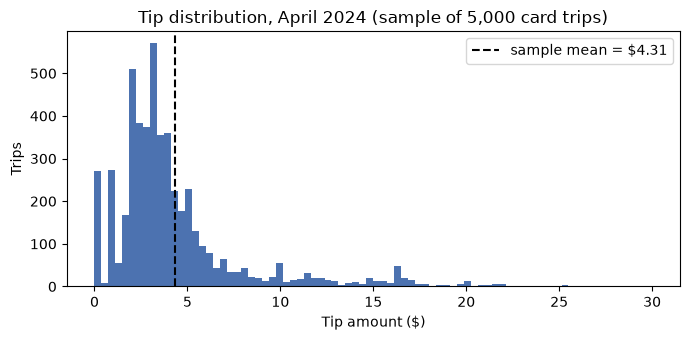

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(sample, bins=80, range=(0, 30), color="#4C72B0")
ax.axvline(mean, color="black", ls="--", label=f"sample mean = ${mean:.2f}")
ax.set(xlabel="Tip amount ($)", ylabel="Trips", title="Tip distribution, April 2024 (sample of 5,000 card trips)")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/01_tip_distribution_april.png", dpi=150)
plt.show()


## Weather data

Daily precipitation for Central Park from the Open-Meteo historical weather API. A day is labelled
**rainy** if total precipitation is at least 1 mm.


In [6]:
url = ("https://archive-api.open-meteo.com/v1/archive?latitude=40.78&longitude=-73.97"
       "&start_date=2024-04-01&end_date=2024-04-30"
       "&daily=precipitation_sum&timezone=America/New_York")
w = pd.DataFrame(requests.get(url, timeout=60).json()["daily"])
w["date"] = pd.to_datetime(w["time"])
w["rainy"] = w.precipitation_sum >= 1.0

df["date"] = df.tpep_pickup_datetime.dt.normalize()
df = df.merge(w[["date", "rainy"]], on="date", how="left")


## Hypothesis test: rainy vs. dry days

The unit of analysis is the **day** (rain is assigned per day, so trips on the same day are not independent).

- H₀: μ_rainy = μ_dry (mean daily tip is the same on rainy and dry days)
- H₁: μ_rainy ≠ μ_dry
- α = 0.05

Welch's t-test (no equal-variance assumption) is paired with the non-parametric Mann-Whitney U test.


In [7]:
daily = df.groupby(["date", "rainy"]).tip_amount.mean().reset_index()
rain = daily[daily.rainy].tip_amount
dry = daily[~daily.rainy].tip_amount
print(f"rainy days = {len(rain)}, dry days = {len(dry)}")

t, p = stats.ttest_ind(rain, dry, equal_var=False)
u, p_mw = stats.mannwhitneyu(rain, dry)
print(f"Welch: t={t:.3f}, p={p:.3f} | Mann-Whitney p={p_mw:.4f}")


rainy days = 15, dry days = 15
Welch: t=-0.728, p=0.473 | Mann-Whitney p=0.2998


In [8]:
diff = rain.mean() - dry.mean()
cohen_d = diff / np.sqrt((rain.var() + dry.var()) / 2)
print(f"Difference (rainy - dry) = ${diff:.3f}, Cohen's d = {cohen_d:.2f}")


Difference (rainy - dry) = $-0.044, Cohen's d = -0.27


In [9]:
from statsmodels.stats.power import TTestIndPower

# Smallest effect (Cohen's d) detectable with 80% power at alpha = 0.05, given 15 vs 15 days
mde = TTestIndPower().solve_power(nobs1=len(rain), ratio=len(dry) / len(rain), alpha=0.05, power=0.8)
print(f"Minimum detectable effect with {len(rain)} vs {len(dry)} days: d = {mde:.2f}")


Minimum detectable effect with 15 vs 15 days: d = 1.06


### Conclusion

**1. Average tip (95% CI)**
- From a random sample of 5,000 card-paid trips, the average tip is about **\$4.31**.
- We are 95% confident the true average tip is between **\$4.20 and \$4.42** (t-interval and bootstrap agree).
- The mean of all cleaned trips (**\$4.34**) falls inside this interval, consistent with the interval covering the true mean.

**2. Rainy vs. dry days (α = 0.05)**
- Rainy days tip about **\$0.04 less** than dry days (15 vs. 15 days).
- Welch t-test: p = 0.473; Mann-Whitney: p = 0.300. Both p-values are **> 0.05**, so we **fail to reject H₀**.
- The effect size is small (Cohen's d = −0.27).

**Result:** There is **no significant evidence** that rain changes the average tip in NYC taxis in April 2024.

**Limitation:** With only 30 days the test has low power: it can only reliably detect a large effect (see the minimum detectable effect above), so a small real difference could go undetected. This means "no evidence of a difference", not "proof of no difference". Comparing whole days also ignores confounders such as day of week, and rain on a given day may fall only during a few hours.

**Next step:** [`02_rain_effect_2024.ipynb`](02_rain_effect_2024.ipynb) extends the analysis to all of 2024, matches each trip to the rain *in its pickup hour*, and controls for confounders with regression.